# Stereographic projections of Silicon

This notebook draws stereographic projections (stereodiagrams) of Silicon with pyEMAPS, step by
step. It follows the *si_stereo.py* sample, one step per cell.

You'll:

1. calculate a stereodiagram and look at its data;
2. check the projection's geometry with a short calculation;
3. display it, with the poles labelled;
4. see how it changes with the zone axis and the tilt.

**Stereographic projection in brief.** Imagine the crystal at the center of a sphere. The
normal to each set of lattice planes $(hkl)$ meets the sphere at a point, the plane's **pole**.
Projecting the poles of the upper hemisphere from the south pole onto the equatorial plane gives
the stereographic projection: a map of the crystal's orientations, with the beam direction, the
zone axis, at its center. A pole at angle $\theta$ from the zone axis lands at

$$r = R \tan\frac{\theta}{2}$$

from the center, where $R$ is the radius of the circle the equator projects to. Microscopists use
stereodiagrams to find zone axes, read the angles between planes, and plan tilts.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment:

```
pip install pyemaps jupyter
```

The [Stereodiagrams guide](https://emlab-solutions.github.io/pyemaps/user_guide/stereo.html) covers the same ground.

## Step 1: Import pyEMAPS and load a crystal

`generateStereo` calculates a stereodiagram, and `showStereo` displays a list of them, each paired
with the microscope controls it was made with.

In [1]:
import math
from importlib.metadata import version

from pyemaps import EMC, Crystal, showStereo

print('pyEMAPS', version('pyemaps'))

silicon = Crystal.from_builtin('Silicon')

pyEMAPS 2.1.1.dev11


## Step 2: Calculate a stereodiagram

`generateStereo` takes the zone axis, the tilt, and the crystal's horizontal axis `xa`. It
returns the poles, each a dictionary with its center `c`, its drawing radius `r` and its Miller
indices `idx`. The projection circle has radius 1.

In [2]:
stereo = silicon.generateStereo(zone=(0, 0, 1))

print(len(stereo), 'poles')
for pole in stereo[:5]:
    h, k, l = (int(i) for i in pole['idx'])
    x, y = pole['c']
    print(f'({h:2d} {k:2d} {l:2d})   center ({x:6.3f}, {y:6.3f})')

229 poles
(-5  0  0)   center ( 0.000,  1.000)
(-4 -3  0)   center (-0.600,  0.800)
(-4 -2  0)   center (-0.447,  0.894)
(-4 -1  0)   center (-0.243,  0.970)
(-4  1  0)   center ( 0.243,  0.970)


## Step 3: Check the projection

For a cubic crystal, the normal to the planes $(hkl)$ is the direction $[hkl]$, so the angle
$\theta$ between a pole and the zone axis $[uvw]$ follows from the dot product:

$$\cos\theta = \frac{h u + k v + l w}{\sqrt{h^2 + k^2 + l^2}\,\sqrt{u^2 + v^2 + w^2}}$$

Each pole's distance from the center should then be $\tan(\theta/2)$:

In [3]:
def angle(a, b):
    """The angle between two directions of a cubic crystal, in degrees."""
    dot = sum(i * j for i, j in zip(a, b))
    return math.degrees(math.acos(dot / math.hypot(*a) / math.hypot(*b)))


zone = (0, 0, 1)
print('  (h k l)    angle    distance   tan(angle/2)')
for pole in stereo:
    hkl = tuple(int(i) for i in pole['idx'])
    if hkl in [(0, 0, 1), (1, 1, 3), (1, 1, 2), (0, 1, 1), (1, 1, 1), (1, 1, 0)]:
        theta = angle(hkl, zone)
        print(f'  ({hkl[0]} {hkl[1]} {hkl[2]})   {theta:6.2f}°   {math.hypot(*pole["c"]):7.4f}'
              f'   {math.tan(math.radians(theta / 2)):9.4f}')

  (h k l)    angle    distance   tan(angle/2)
  (1 1 0)    90.00°    1.0000      1.0000
  (0 0 1)     0.00°    0.0000      0.0000
  (0 1 1)    45.00°    0.4142      0.4142
  (1 1 1)    54.74°    0.5176      0.5176
  (1 1 2)    35.26°    0.3178      0.3178
  (1 1 3)    25.24°    0.2239      0.2239


They agree. The poles at 90°, such as (1 1 0), lie on the circle itself: planes parallel to
the beam, the ones that diffract in a zone axis pattern.

## Step 4: Display it

`showStereo` draws each pole as a small circle. `iShow=True` labels the poles with their Miller
indices, and `zLimit` limits the labels to the poles whose indices are all within it, to keep the
plot readable. The [001] zone axis shows Silicon's four-fold symmetry.

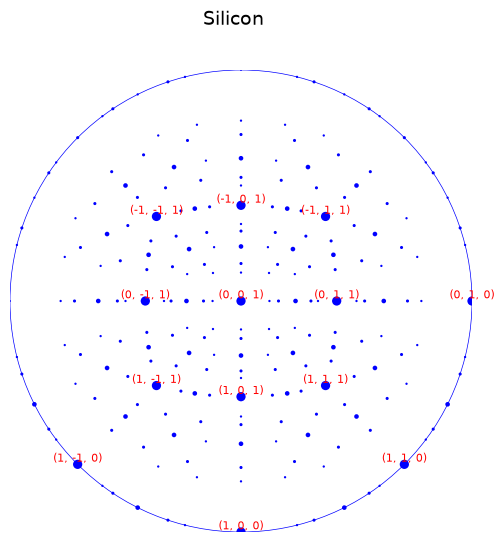

In [4]:
showStereo([(EMC(zone=(0, 0, 1)), stereo)], name='Silicon', iShow=True, zLimit=1)

## Step 5: Zone axis

The *si_stereo.py* sample makes stereodiagrams at the zone axes $[i\;\bar{i}\;1]$, for $i$ from
−3 to 2. Each one puts a different direction at the center. At $[\bar{1}\,1\,1]$ the pattern of
poles has three-fold symmetry; at [001], four-fold.

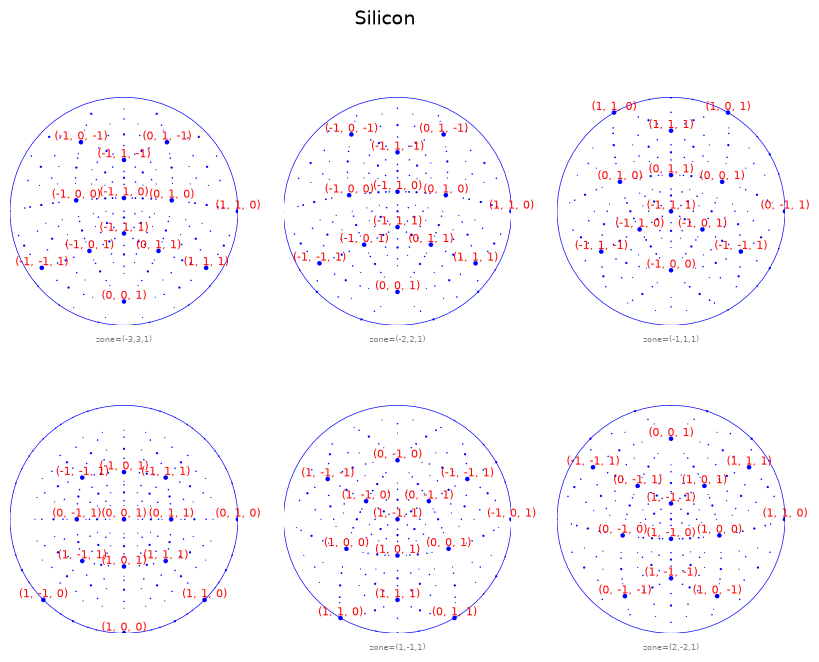

In [5]:
zones = []
for i in range(-3, 3):
    emc = EMC(zone=(i, -i, 1))
    zones.append((emc, silicon.generateStereo(zone=emc.zone)))

showStereo(zones, name='Silicon', layout='table', iShow=True, zLimit=1)

## Step 6: Tilt

Tilting the crystal rotates the sphere of poles, so the whole projection shifts. The tilt series
of the sample goes from −1.5° to 1° about the x axis, in steps of 0.5°.

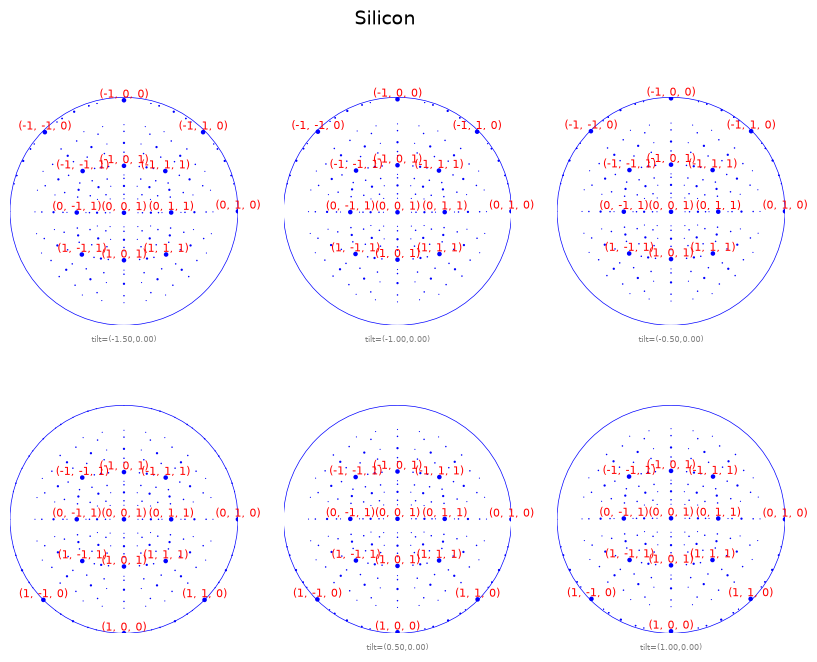

In [6]:
tilts = []
for i in range(-3, 3):
    emc = EMC(tilt=(i * 0.5, 0.0))
    tilts.append((emc, silicon.generateStereo(tilt=emc.tilt)))

showStereo(tilts, name='Silicon', layout='table', iShow=True, zLimit=1)

A degree or so of tilt moves the poles only slightly: that's the scale on which a
microscopist tilts a crystal onto a zone axis.

## Step 7: Save the figures

`bSave=True` also saves each figure as a PNG, in the `stereo` folder of the pyEMAPS data folder:
the folder named by the `PYEMAPS_DATA` environment variable, or the current folder if it isn't
set. The file name is printed.

image saved to: C:\pyemaps_data\stereo\Silicon-20261114115357.png


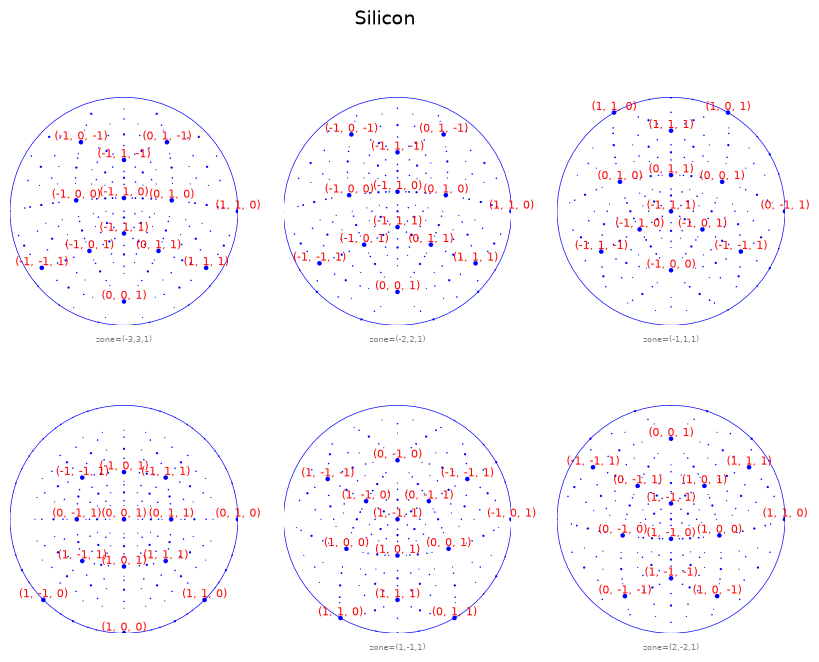

In [7]:
showStereo(zones, name='Silicon', layout='table', iShow=True, zLimit=1, bSave=True)

## Going further: many stereodiagrams in parallel

*si_stereo.py* runs the calculations in parallel processes. Its `generate_stereodiagrams`
function makes the same six-stereodiagram series as above, and you can call it here. pyEMAPS
installs the samples as `pyemaps.samples`:

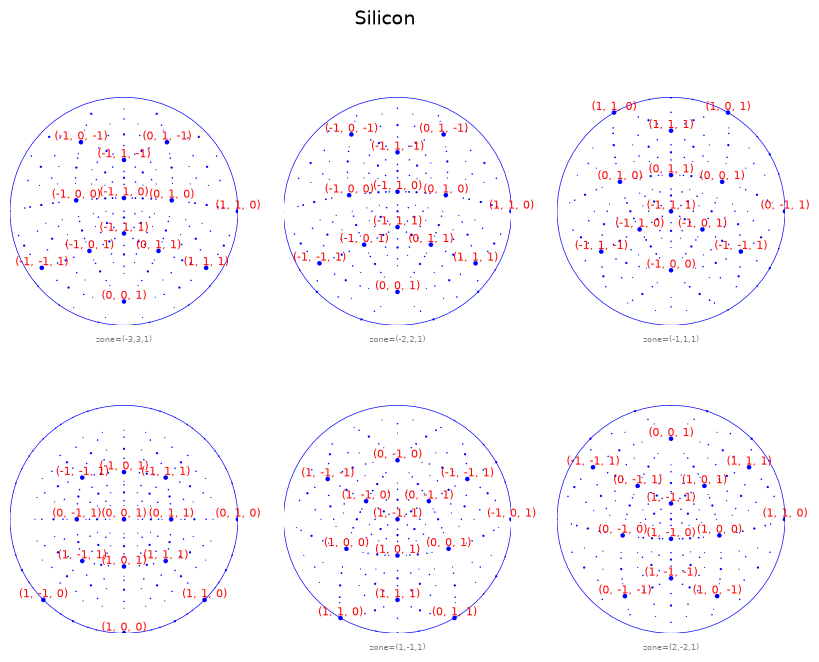

In [8]:
from pyemaps.samples.si_stereo import generate_stereodiagrams

series = generate_stereodiagrams('zone')
showStereo(series, name='Silicon', layout='table', iShow=True, zLimit=1)

To write your own parallel code, see *si_stereo.py*, which `pyemaps -cp samples` copies into
a *pyemaps_samples* folder. In a notebook on Windows, the function each process runs must come
from an importable module, such as `pyemaps.samples.si_stereo` or a `.py` file of your own; a
function defined in a notebook cell can't be sent to another process.

## Try it yourself

1. **Angles between planes.** Use `angle` to find the angle between (1 1 1) and (1 −1 1). Find
   both poles on the [001] stereodiagram: are they the right distance apart?
2. **Zone axes.** Every pole on the circle of the [001] stereodiagram is a plane parallel to the
   beam. Compare them with the diffracted beams of the [001] pattern in the
   [kinematic diffraction notebook](si_dif.ipynb).
3. **Another axis.** Make the [111] stereodiagram (`zone=(1, 1, 1)`). Which poles lie on its
   circle?
4. **Labels.** Show the [001] stereodiagram with `zLimit=2`. Which new poles are labelled?

## Next

- The kinematic diffraction notebook, [si_dif.ipynb](si_dif.ipynb), and the pattern indexing
  notebook, [al_ediom.ipynb](al_ediom.ipynb), which uses the stereographic triangle.
- The [Stereodiagrams guide](https://emlab-solutions.github.io/pyemaps/user_guide/stereo.html), and the references for
  [`generateStereo`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.generateStereo)
  and [`showStereo`](https://emlab-solutions.github.io/pyemaps/api/display.html#pyemaps.display.showStereo).

## Further reading

J. M. Zuo and J. C. H. Spence, *Advanced Transmission Electron Microscopy* (Springer, New York,
2017), [doi:10.1007/978-1-4939-6607-3](https://doi.org/10.1007/978-1-4939-6607-3):

- chapter 3, *The Geometry of Electron Diffraction Patterns*, for zone axes and crystal
  orientations in Steps 3 to 6;
- chapter 11, *Crystal Symmetry*, for the symmetry of the stereodiagrams in Steps 4 and 5.